# 🐶 Dog Vision — End-to-End Multi-Class Dog Breed Classification

**Problem:** Given a photo of a dog, identify its breed out of **120 possible breeds**.

**Data:** [Kaggle — Dog Breed Identification](https://www.kaggle.com/c/dog-breed-identification/data)
* `train/` — 10,222 labelled images
* `test/` — 10,357 unlabelled images
* `labels.csv` — image id → breed

**Evaluation:** Kaggle scores a submission file of **prediction probabilities for every breed** for every test image (multi-class log loss).

**Approach:** Transfer learning with a **ResNet101V2** pretrained on ImageNet, fed by a `tf.data` input pipeline, trained in Google Colab on a GPU.

**Workflow:**
1. Setup & get the data
2. Explore the data
3. Turn labels into numbers (one-hot encoding)
4. Create a train/validation split
5. Preprocess images into tensors & batch them (`tf.data`)
6. Build the model (transfer learning)
7. Train on a subset (fast experiments) with TensorBoard + EarlyStopping
8. Evaluate predictions
9. Save & reload the model
10. Train on the full dataset
11. Predict on the test set & create a Kaggle submission
12. Predict on custom images

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

## 1. Setup

In [1]:
# Mount Google Drive (the dataset lives in MyDrive/Dog-Vision)
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os
import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from IPython.display import Image, display

print("TensorFlow version:", tf.__version__)
print("GPU available:", "yes ✅" if tf.config.list_physical_devices("GPU") else "no ❌ (Runtime → Change runtime type → GPU)")

TensorFlow version: 2.21.0
GPU available: yes ✅


In [3]:
# All paths in one place
DATA_DIR   = "/content/drive/MyDrive/Dog-Vision"
TRAIN_DIR  = os.path.join(DATA_DIR, "train")
TEST_DIR   = os.path.join(DATA_DIR, "test")
CUSTOM_DIR = os.path.join(DATA_DIR, "my-dog-photos")
MODEL_DIR  = os.path.join(DATA_DIR, "models")
LOG_DIR    = os.path.join(DATA_DIR, "logs")

os.makedirs(MODEL_DIR, exist_ok=True)

## 2. Explore the data

In [4]:
labels = pd.read_csv(os.path.join(DATA_DIR, "labels.csv"))
print(labels.describe())
labels.head()

                                      id               breed
count                              10222               10222
unique                             10222                 120
top     fff43b07992508bc822f33d8ffd902ae  scottish_deerhound
freq                                   1                 126


,id,breed
0,000bec180eb18c7604dcecc8fe0dba07,boston_bull
1,001513dfcb2ffafc82cccf4d8bbaba97,dingo
2,001cdf01b096e06d78e9e5112d419397,pekinese
3,00214f311d5d2247d5dfe4fe24b2303d,bluetick
4,0021f9ceb3235effd7fcde7f7538ed62,golden_retriever


Median images per breed: 82.0


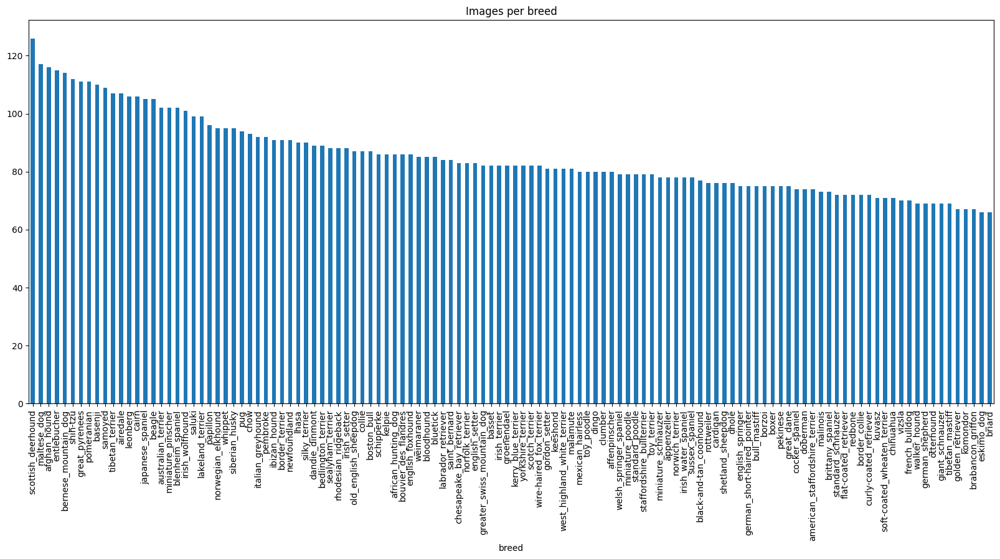

In [5]:
# How many images are there of each breed?
labels["breed"].value_counts().plot(kind="bar", figsize=(20, 8), title="Images per breed");
print("Median images per breed:", labels["breed"].value_counts().median())

Every breed has roughly 60–126 images, so the classes are reasonably balanced and **accuracy** is a fair metric.

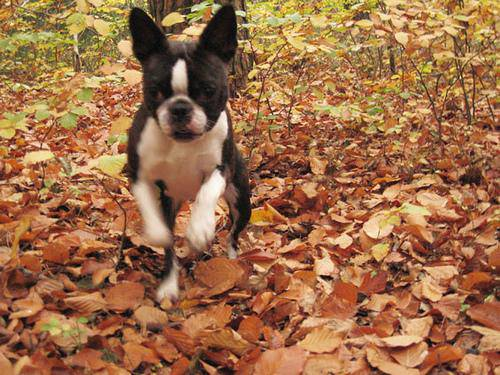

In [6]:
# Look at one image
Image(os.path.join(TRAIN_DIR, labels["id"][0] + ".jpg"))

## 3. Get images and their labels

Build the full file path for every training image, and check it matches the number of files on disk.

In [7]:
filenames = [os.path.join(TRAIN_DIR, image_id + ".jpg") for image_id in labels["id"]]
filenames[:3]

['/content/drive/MyDrive/Dog-Vision/train/000bec180eb18c7604dcecc8fe0dba07.jpg',
 '/content/drive/MyDrive/Dog-Vision/train/001513dfcb2ffafc82cccf4d8bbaba97.jpg',
 '/content/drive/MyDrive/Dog-Vision/train/001cdf01b096e06d78e9e5112d419397.jpg']

In [8]:
actual_files = os.listdir(TRAIN_DIR)
print("Files on disk:", len(actual_files))
print("Filenames    :", len(filenames))
assert len(actual_files) == len(filenames), "Filenames do not match the files on disk, check TRAIN_DIR"
print("Filenames match the number of files ✅")

Files on disk: 10222
Filenames    : 10222
Filenames match the number of files ✅


Machine learning models can't take strings as input, so the breed names have to become numbers.
We **one-hot encode** them: each label becomes a vector of 120 booleans, with `True` at the index of its breed.

In [9]:
breed_labels = labels["breed"].to_numpy()
unique_breeds = np.unique(breed_labels)          # sorted list of the 120 breeds
print("Number of breeds:", len(unique_breeds))

Number of breeds: 120


In [10]:
boolean_labels = [label == unique_breeds for label in breed_labels]

# Example: the first label
print(breed_labels[0])
print("Index of breed:", np.where(unique_breeds == breed_labels[0])[0][0])
print("argmax of one-hot vector:", boolean_labels[0].argmax())
print(boolean_labels[0].astype(int))

boston_bull
Index of breed: 19
argmax of one-hot vector: 19
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0]


## 4. Create a validation set

Kaggle's test set has no labels, so we hold out part of the training data to check how well the model generalises.

To iterate quickly we start with a **subset** of ~1,000 images. Once the pipeline works we train on all 10,222.

In [70]:
X = filenames
y = boolean_labels

NUM_IMAGES = 10000 #@param {type:"slider", min:1000, max:10000, step:1000}

In [71]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(X[:NUM_IMAGES],
                                                  y[:NUM_IMAGES],
                                                  test_size=0.2,
                                                  random_state=42)
len(X_train), len(y_train), len(X_val), len(y_val)

(8000, 8000, 2000, 2000)

## 5. Preprocess images into tensors

For each image file path we:
1. Read the file
2. Decode the JPEG into a tensor with 3 colour channels (RGB)
3. Convert the pixel values from 0–255 integers to 0–1 floats
4. Resize to `224 x 224` (the input size the model expects)

In [72]:
IMG_SIZE = 224

def preprocess_image(image_path, img_size=IMG_SIZE):
    # Turns an image file path into a normalised (img_size, img_size, 3) float tensor.
    image = tf.io.read_file(image_path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.convert_image_dtype(image, tf.float32)   # 0-255 -> 0-1
    image = tf.image.resize(image, size=[img_size, img_size])
    return image

def get_image_label(image_path, label):
    # Returns a (processed image, label) tuple.
    return preprocess_image(image_path), label

In [73]:
# Check it works on one image
sample = preprocess_image(filenames[42])
sample.shape, float(tf.reduce_min(sample)), float(tf.reduce_max(sample))

(TensorShape([224, 224, 3]), 0.0, 1.0)

### Turn the data into batches

Training on 10,000+ images at once won't fit in memory, so we feed the model **batches of 32**.
`tf.data` builds an efficient pipeline:
* `shuffle` — only for training data, so the model doesn't learn the order
* `map(..., num_parallel_calls=AUTOTUNE)` — load & preprocess images in parallel
* `batch` — group into batches of 32
* `prefetch` — prepare the next batch on the CPU while the GPU trains on the current one

In [74]:
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

def create_data_batches(X, y=None, batch_size=BATCH_SIZE, valid_data=False, test_data=False):
    # Test data has no labels -> only images.
    if test_data:
        print("Creating test data batches...")
        data = tf.data.Dataset.from_tensor_slices(tf.constant(X))
        return data.map(preprocess_image, num_parallel_calls=AUTOTUNE).batch(batch_size).prefetch(AUTOTUNE)

    data = tf.data.Dataset.from_tensor_slices((tf.constant(X), tf.constant(y)))

    # Validation data doesn't need shuffling.
    if valid_data:
        print("Creating validation data batches...")
        return data.map(get_image_label, num_parallel_calls=AUTOTUNE).batch(batch_size).prefetch(AUTOTUNE)

    # Training data: shuffle the file paths first (cheap) and then load the images.
    print("Creating training data batches...")
    data = data.shuffle(buffer_size=len(X))
    return data.map(get_image_label, num_parallel_calls=AUTOTUNE).batch(batch_size).prefetch(AUTOTUNE)

In [75]:
train_data = create_data_batches(X_train, y_train)
val_data = create_data_batches(X_val, y_val, valid_data=True)

train_data.element_spec, val_data.element_spec

Creating training data batches...
Creating validation data batches...


((TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None),
  TensorSpec(shape=(None, 120), dtype=tf.bool, name=None)),
 (TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None),
  TensorSpec(shape=(None, 120), dtype=tf.bool, name=None)))

### Visualise a batch

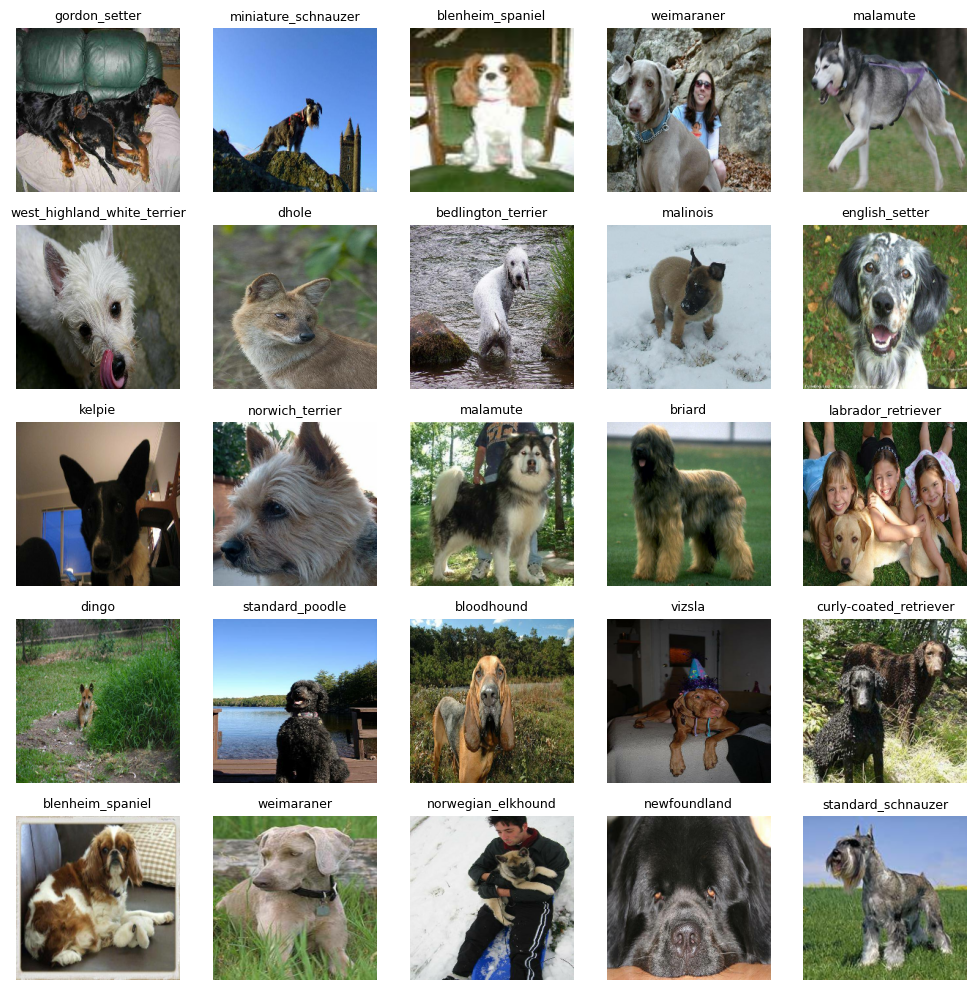

In [76]:
def show_25_images(images, labels):
    plt.figure(figsize=(10, 10))
    for i in range(25):
        ax = plt.subplot(5, 5, i + 1)
        plt.imshow(images[i])
        plt.title(unique_breeds[labels[i].argmax()], fontsize=9)
        plt.axis("off")
    plt.tight_layout()
    plt.show()

train_images, train_labels = next(train_data.as_numpy_iterator())
show_25_images(train_images, train_labels)

## 6. Build the model — transfer learning

Instead of training a CNN from scratch (which would need far more than 10k images), we use **ResNet101V2**
already trained on ImageNet (1.2M+ images, 1,000 classes, including many dog breeds). It already knows how to
detect edges, textures, fur and faces. We:

* **Freeze** the pretrained base (`trainable = False`) and use it as a feature extractor → 2048 features per image
* Add our own **classification head**: `Dropout` + `Dense(120, softmax)` → a probability for each breed

Extra layers in the model:
* `Rescaling(2, offset=-1)` — ResNetV2 was trained on pixels in the range **[-1, 1]**, our pipeline outputs [0, 1]
* **Data augmentation** (random flip / rotation / zoom) — only active during training; creates slightly different
  versions of each image every epoch, which reduces overfitting

| | Value |
|---|---|
| Input shape | `(None, 224, 224, 3)` — a batch of RGB images |
| Output shape | `(None, 120)` — a probability for each breed |
| Loss | Categorical cross-entropy (multi-class, one-hot labels) |
| Optimizer | Adam |
| Metrics | Accuracy, Top-5 accuracy |

In [77]:
INPUT_SHAPE = (IMG_SIZE, IMG_SIZE, 3)
NUM_CLASSES = len(unique_breeds)

def create_model(input_shape=INPUT_SHAPE, num_classes=NUM_CLASSES):
    print("Building model with ResNet101V2 (ImageNet weights)")

    base_model = keras.applications.ResNet101V2(include_top=False,
                                                weights="imagenet",
                                                input_shape=input_shape,
                                                pooling="avg")
    base_model.trainable = False   # freeze the pretrained weights

    data_augmentation = keras.Sequential([
        keras.layers.RandomFlip("horizontal"),
        keras.layers.RandomRotation(0.1),
        keras.layers.RandomZoom(0.1),
    ], name="data_augmentation")

    inputs = keras.Input(shape=input_shape)
    x = data_augmentation(inputs)
    x = keras.layers.Rescaling(2.0, offset=-1.0, name="scale_to_minus1_1")(x)   # [0,1] -> [-1,1]
    x = base_model(x, training=False)
    x = keras.layers.Dropout(0.2)(x)
    outputs = keras.layers.Dense(num_classes, activation="softmax")(x)

    model = keras.Model(inputs, outputs, name="dog_vision")
    model.compile(loss=keras.losses.CategoricalCrossentropy(),
                  optimizer=keras.optimizers.Adam(),
                  metrics=["accuracy", keras.metrics.TopKCategoricalAccuracy(k=5, name="top5_accuracy")])
    return model

In [78]:
model = create_model()
model.summary()

Building model with ResNet101V2 (ImageNet weights)


Model: "dog_vision"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_16 (InputLayer)     │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ scale_to_minus1_1 (Rescaling)   │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet101v2 (Functional)        │ (None, 2048)           │    42,626,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 120)            │       245,880 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 42,872,440 (163.55 MB)

 Trainable params: 245,880 (960.47 KB)

 Non-trainable params: 42,626,560 (162.61 MB)

## 7. Callbacks

* **TensorBoard** — logs loss/accuracy per epoch so we can visualise training
* **EarlyStopping** — stops training when the validation accuracy stops improving for 3 epochs and restores the best weights (prevents overfitting and saves time)

In [79]:
def create_tensorboard_callback():
    logdir = os.path.join(LOG_DIR, datetime.datetime.now().strftime("%Y%m%d-%H%M%S"))
    return keras.callbacks.TensorBoard(log_dir=logdir)

def create_early_stopping(monitor="val_accuracy"):
    return keras.callbacks.EarlyStopping(monitor=monitor, patience=3, restore_best_weights=True)

## 8. Train on the subset

In [80]:
NUM_EPOCHS = 100 #@param {type:"slider", min:10, max:100, step:10}

In [81]:
def train_model(train_data, val_data, epochs=NUM_EPOCHS):
    model = create_model()
    history = model.fit(train_data,
                        epochs=epochs,
                        validation_data=val_data,
                        callbacks=[create_tensorboard_callback(), create_early_stopping()])
    return model, history

In [82]:
model, history = train_model(train_data, val_data)

Building model with ResNet101V2 (ImageNet weights)
Epoch 1/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 87s 279ms/step - accuracy: 0.4756 - loss: 2.1727 - top5_accuracy: 0.7576 - val_accuracy: 0.7140 - val_loss: 0.9928 - val_top5_accuracy: 0.9460
Epoch 2/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 87s 298ms/step - accuracy: 0.6898 - loss: 1.0752 - top5_accuracy: 0.9291 - val_accuracy: 0.7425 - val_loss: 0.8754 - val_top5_accuracy: 0.9600
Epoch 3/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 66s 263ms/step - accuracy: 0.7400 - loss: 0.8638 - top5_accuracy: 0.9521 - val_accuracy: 0.7305 - val_loss: 0.9165 - val_top5_accuracy: 0.9525
Epoch 4/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 66s 262ms/step - accuracy: 0.7804 - loss: 0.7390 - top5_accuracy: 0.9660 - val_accuracy: 0.7370 - val_loss: 0.9124 - val_top5_accuracy: 0.9540
Epoch 5/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 66s 263ms/step - accuracy: 0.8033 - loss: 0.6397 - top5_accuracy: 0.9749 - val_accuracy: 0.7475 - val_loss: 0.8925 - val_top5_accuracy: 0.9555
Epoch 6/100
250/250 ━━━━━━━━━

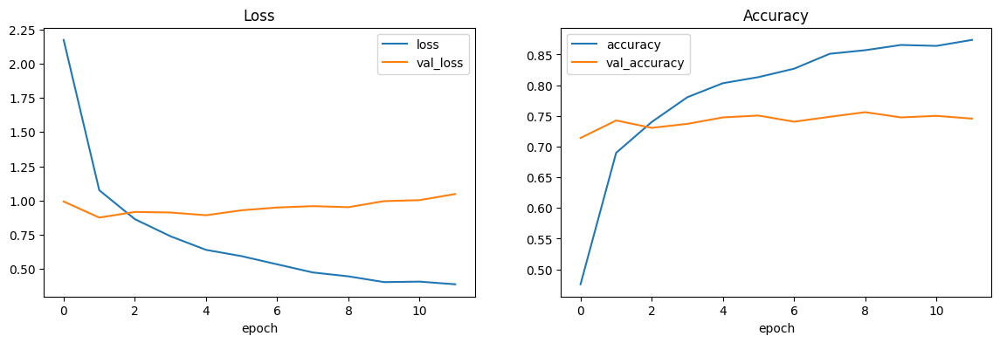

In [83]:
def plot_history(history):
    hist = pd.DataFrame(history.history)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))
    hist[["loss", "val_loss"]].plot(ax=ax1, title="Loss", xlabel="epoch")
    hist[["accuracy", "val_accuracy"]].plot(ax=ax2, title="Accuracy", xlabel="epoch")
    plt.show()

plot_history(history)

In [84]:
%load_ext tensorboard
%tensorboard --logdir {LOG_DIR}

The tensorboard extension is already loaded. To reload it, use:
  %reload_ext tensorboard


Reusing TensorBoard on port 6006 (pid 7404), started 2:50:48 ago. (Use '!kill 7404' to kill it.)

<IPython.core.display.Javascript object>

## 9. Make and evaluate predictions

The model outputs a **probability for each of the 120 breeds** (they sum to 1).
The predicted breed is the one with the highest probability (`argmax`).

In [85]:
predictions = model.predict(val_data, verbose=1)
predictions.shape

63/63 ━━━━━━━━━━━━━━━━━━━━ 21s 257ms/step


(2000, 120)

In [86]:
IDX = 1
print(f"Sum of probabilities: {np.sum(predictions[IDX]):.2f}")
print(f"Max probability     : {np.max(predictions[IDX]):.4f}")
print(f"Max index           : {np.argmax(predictions[IDX])}")
print(f"Predicted label     : {unique_breeds[np.argmax(predictions[IDX])]}")

Sum of probabilities: 1.00
Max probability     : 0.9996
Max index           : 87
Predicted label     : pomeranian


In [87]:
def get_pred_label(prediction_probabilities):
    # Turns an array of prediction probabilities into a breed name.
    return unique_breeds[np.argmax(prediction_probabilities)]

def unbatchify(data):
    # Takes a batched dataset of (image, label) and returns separate arrays of images and breed names.
    images, labels_ = [], []
    for image, label in data.unbatch().as_numpy_iterator():
        images.append(image)
        labels_.append(unique_breeds[np.argmax(label)])
    return images, labels_

val_images, val_labels = unbatchify(val_data)
val_labels[1], get_pred_label(predictions[1])

('pomeranian', 'pomeranian')

### Overall validation metrics

In [88]:
pred_labels = np.array([get_pred_label(p) for p in predictions])
true_labels = np.array(val_labels)

accuracy = np.mean(pred_labels == true_labels)

true_idx = np.array([np.where(unique_breeds == l)[0][0] for l in true_labels])
top5 = np.argsort(predictions, axis=1)[:, -5:]
top5_accuracy = np.mean([t in row for t, row in zip(true_idx, top5)])

# Log loss = the metric Kaggle uses (lower is better)
log_loss = -np.mean(np.log(np.clip(predictions[np.arange(len(true_idx)), true_idx], 1e-15, 1)))

print(f"Validation accuracy      : {accuracy:.2%}")
print(f"Validation top-5 accuracy: {top5_accuracy:.2%}")
print(f"Validation log loss      : {log_loss:.4f}")

Validation accuracy      : 75.60%
Validation top-5 accuracy: 95.55%
Validation log loss      : 0.9513


In [30]:
# Which breeds get mixed up the most?
mistakes = pd.DataFrame({"true": true_labels, "predicted": pred_labels})
mistakes = mistakes[mistakes["true"] != mistakes["predicted"]]
mistakes.value_counts().head(10)

true                predicted           
kelpie              schipperke              3
dandie_dinmont      cairn                   2
appenzeller         bernese_mountain_dog    1
airedale            miniature_pinscher      1
afghan_hound        tibetan_terrier         1
appenzeller         entlebucher             1
                    cardigan                1
blenheim_spaniel    brittany_spaniel        1
australian_terrier  yorkshire_terrier       1
bluetick            border_terrier          1
Name: count, dtype: int64

### Visualise predictions

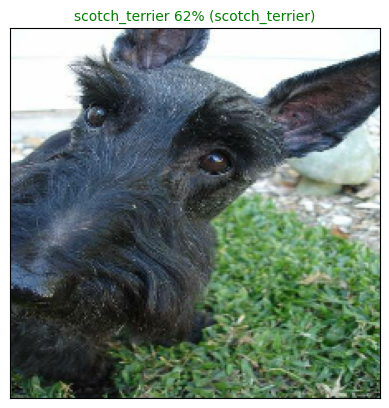

In [31]:
def plot_pred(prediction_probabilities, labels, images, n=1):
    # Shows image n with its predicted breed, confidence and true breed (green = correct, red = wrong).
    pred_prob, true_label, image = prediction_probabilities[n], labels[n], images[n]
    pred_label = get_pred_label(pred_prob)

    plt.imshow(image)
    plt.xticks([]); plt.yticks([])
    color = "green" if pred_label == true_label else "red"
    plt.title(f"{pred_label} {np.max(pred_prob) * 100:.0f}% ({true_label})", color=color, fontsize=10)

def plot_pred_conf(prediction_probabilities, labels, n=1):
    # Plots the model's top 10 most confident breeds for sample n.
    pred_prob, true_label = prediction_probabilities[n], labels[n]
    top_10_idx = pred_prob.argsort()[-10:][::-1]
    top_10_labels = unique_breeds[top_10_idx]

    bars = plt.bar(np.arange(10), pred_prob[top_10_idx], color="grey")
    plt.xticks(np.arange(10), top_10_labels, rotation="vertical")
    if true_label in top_10_labels:
        bars[np.argmax(top_10_labels == true_label)].set_color("green")

plot_pred(predictions, val_labels, val_images, n=1)

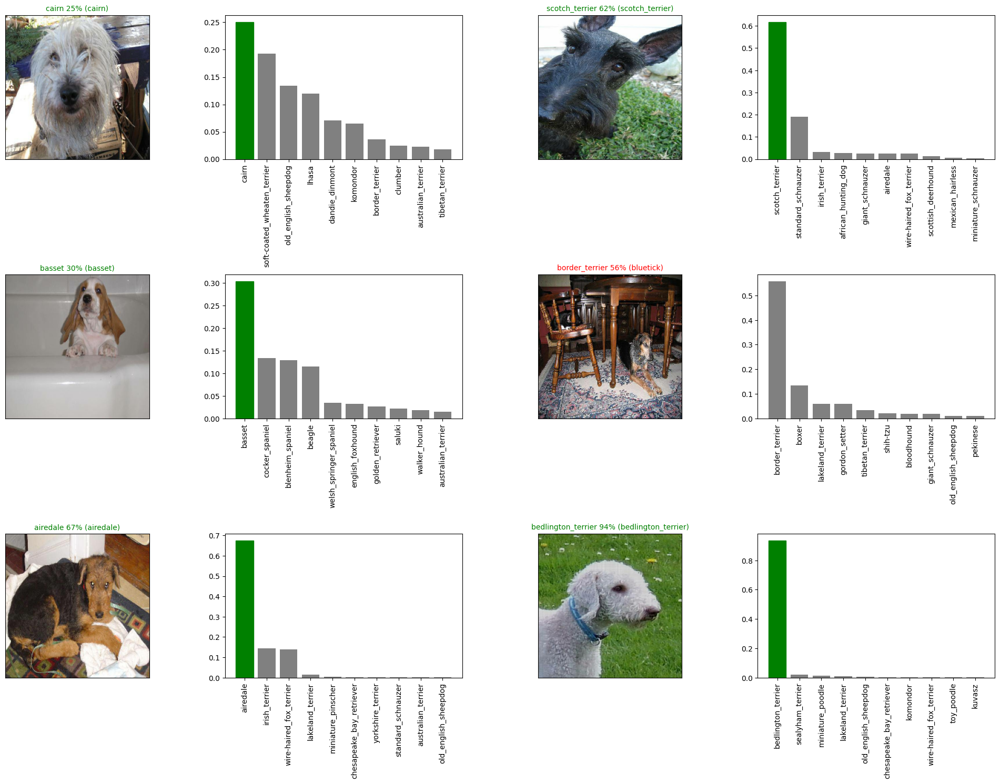

In [32]:
# Several predictions with their top-10 confidence bars
i_multiplier = 0
num_rows, num_cols = 3, 2
num_images = num_rows * num_cols

plt.figure(figsize=(10 * num_cols, 5 * num_rows))
for i in range(num_images):
    plt.subplot(num_rows, 2 * num_cols, 2 * i + 1)
    plot_pred(predictions, val_labels, val_images, n=i + i_multiplier)
    plt.subplot(num_rows, 2 * num_cols, 2 * i + 2)
    plot_pred_conf(predictions, val_labels, n=i + i_multiplier)
plt.tight_layout(h_pad=1.0)
plt.show()

## 10. Save and reload the model

Training takes time, so we save the trained model (architecture + weights + optimizer state) to a `.keras` file.

In [33]:
def save_model(model, suffix=None):
    timestamp = datetime.datetime.now().strftime("%Y%m%d-%H%M%S")
    model_path = os.path.join(MODEL_DIR, f"{timestamp}-{suffix}.keras")
    print(f"Saving model to: {model_path}...")
    model.save(model_path)
    return model_path

def load_model(model_path):
    print(f"Loading saved model from: {model_path}")
    return keras.models.load_model(model_path)

In [34]:
subset_model_path = save_model(model, suffix="1000-images-resnet101v2-adam")
loaded_subset_model = load_model(subset_model_path)

# The reloaded model should give the same results
print("Original:", model.evaluate(val_data, verbose=0))
print("Reloaded:", loaded_subset_model.evaluate(val_data, verbose=0))

Saving model to: /content/drive/MyDrive/Dog-Vision/models/20261010-055926-1000-images-resnet101v2-adam.keras...
Loading saved model from: /content/drive/MyDrive/Dog-Vision/models/20261010-055926-1000-images-resnet101v2-adam.keras
Original: [1.477579951286316, 0.6399999856948853, 0.875]
Reloaded: [1.477579951286316, 0.6399999856948853, 0.875]


## 11. Train on the full dataset

The pipeline works, so now we train on all **10,222** images. There is no validation set here
(we use all data for training), so EarlyStopping watches the **training accuracy** instead.

> ⏱ With a Colab T4 GPU this takes noticeably longer than the subset. The first epoch is the slowest because images are read from Google Drive.

In [35]:
full_data = create_data_batches(X, y)

Creating training data batches...


In [36]:
full_model = create_model()
full_model.fit(full_data,
               epochs=NUM_EPOCHS,
               callbacks=[create_tensorboard_callback(), create_early_stopping(monitor="accuracy")])

Building model with ResNet101V2 (ImageNet weights)
Epoch 1/100
320/320 ━━━━━━━━━━━━━━━━━━━━ 84s 212ms/step - accuracy: 0.5105 - loss: 2.0137 - top5_accuracy: 0.7844
Epoch 2/100
320/320 ━━━━━━━━━━━━━━━━━━━━ 68s 212ms/step - accuracy: 0.6918 - loss: 1.0727 - top5_accuracy: 0.9299
Epoch 3/100
320/320 ━━━━━━━━━━━━━━━━━━━━ 82s 212ms/step - accuracy: 0.7410 - loss: 0.8818 - top5_accuracy: 0.9528
Epoch 4/100
320/320 ━━━━━━━━━━━━━━━━━━━━ 67s 210ms/step - accuracy: 0.7721 - loss: 0.7648 - top5_accuracy: 0.9644
Epoch 5/100
320/320 ━━━━━━━━━━━━━━━━━━━━ 82s 211ms/step - accuracy: 0.7872 - loss: 0.6879 - top5_accuracy: 0.9720
Epoch 6/100
320/320 ━━━━━━━━━━━━━━━━━━━━ 69s 214ms/step - accuracy: 0.8068 - loss: 0.6245 - top5_accuracy: 0.9762
Epoch 7/100
320/320 ━━━━━━━━━━━━━━━━━━━━ 68s 211ms/step - accuracy: 0.8172 - loss: 0.5883 - top5_accuracy: 0.9799
Epoch 8/100
320/320 ━━━━━━━━━━━━━━━━━━━━ 68s 211ms/step - accuracy: 0.8280 - loss: 0.5364 - top5_accuracy: 0.9818
Epoch 9/100
320/320 ━━━━━━━━━━━━━━━━━

In [37]:
full_model_path = save_model(full_model, suffix="full-image-set-resnet101v2-adam")

# Also export a copy + the breed list with fixed names for the Gradio demo app (app.py)
full_model.save(os.path.join(MODEL_DIR, "dog_vision_full.keras"))
pd.Series(unique_breeds).to_json(os.path.join(MODEL_DIR, "breeds.json"), orient="values")

Saving model to: /content/drive/MyDrive/Dog-Vision/models/20261010-064318-full-image-set-resnet101v2-adam.keras...


In [38]:
loaded_full_model = load_model(full_model_path)

Loading saved model from: /content/drive/MyDrive/Dog-Vision/models/20261010-064318-full-image-set-resnet101v2-adam.keras


## 12. Predict on the test set & create a Kaggle submission

The test images go through **exactly the same preprocessing** as the training images.
Kaggle wants a CSV with one row per test image: the `id` plus a probability column for each of the 120 breeds.

In [39]:
test_filenames = [os.path.join(TEST_DIR, fname) for fname in sorted(os.listdir(TEST_DIR))]
print("Test images:", len(test_filenames))

test_data = create_data_batches(test_filenames, test_data=True)

Test images: 10357
Creating test data batches...


In [40]:
test_predictions = loaded_full_model.predict(test_data, verbose=1)
np.save(os.path.join(DATA_DIR, "test_predictions.npy"), test_predictions)
test_predictions.shape

324/324 ━━━━━━━━━━━━━━━━━━━━ 240s 713ms/step


(10357, 120)

In [41]:
preds_df = pd.DataFrame(test_predictions, columns=unique_breeds)
preds_df.insert(0, "id", [os.path.splitext(os.path.basename(path))[0] for path in test_filenames])

submission_path = os.path.join(DATA_DIR, "full_model_predictions_submission.csv")
preds_df.to_csv(submission_path, index=False)
print("Saved submission to", submission_path)
preds_df.head()

Saved submission to /content/drive/MyDrive/Dog-Vision/full_model_predictions_submission.csv


,id,affenpinscher,afghan_hound,african_hunting_dog,airedale,american_staffordshire_terrier,appenzeller,australian_terrier,basenji,basset,...,toy_poodle,toy_terrier,vizsla,walker_hound,weimaraner,welsh_springer_spaniel,west_highland_white_terrier,whippet,wire-haired_fox_terrier,yorkshire_terrier
0,000621fb3cbb32d8935728e48679680e,6.718977e-15,3.117315e-16,4.996149e-15,1.405147e-17,5.543048e-17,1.234746e-19,6.859518e-17,1.275333e-17,9.272847e-16,...,1.235080e-12,3.272909e-14,8.870310e-17,3.746679e-18,8.106975e-17,3.487392e-17,2.137280e-17,1.300576e-16,3.325484e-17,1.538471e-14
1,00102ee9d8eb90812350685311fe5890,2.290678e-15,4.739018e-15,3.025880e-16,3.983883e-16,7.708306e-13,1.852382e-15,3.182629e-18,6.698251e-14,7.974880e-21,...,5.138772e-11,5.094208e-13,1.396874e-17,6.056859e-15,2.456009e-17,4.447917e-14,1.201200e-08,2.696903e-14,2.721869e-13,8.341011e-13
2,0012a730dfa437f5f3613fb75efcd4ce,6.946151e-17,2.984518e-09,2.799998e-16,6.556113e-11,1.462700e-10,6.420982e-16,5.573036e-14,3.333724e-19,7.520309e-14,...,2.049836e-16,7.624875e-15,6.300330e-13,3.665003e-09,1.135968e-08,1.744191e-07,3.125166e-13,5.919682e-10,6.101884e-11,5.036517e-18
3,001510bc8570bbeee98c8d80c8a95ec1,5.336332e-04,1.074528e-03,2.255102e-11,3.622168e-10,1.392479e-12,3.386577e-10,3.981315e-11,7.313651e-05,3.792286e-07,...,9.311846e-09,1.106099e-10,1.595577e-06,7.990859e-10,1.814885e-09,7.833693e-05,4.812890e-11,1.285929e-03,4.388596e-10,1.259661e-06
4,001a5f3114548acdefa3d4da05474c2e,1.950137e-09,4.084190e-12,3.434806e-17,3.531319e-15,2.825180e-16,3.574130e-23,1.317572e-13,3.216934e-15,3.631633e-12,...,2.823930e-13,2.226647e-16,2.723343e-15,6.728825e-16,7.743940e-17,6.009334e-12,1.419197e-14,2.821566e-13,1.890953e-12,2.244077e-16


## 13. Predict on your own images

Put some dog photos in `MyDrive/Dog-Vision/my-dog-photos/` and run the cells below.

In [47]:
custom_paths = [os.path.join(CUSTOM_DIR, fname) for fname in os.listdir(CUSTOM_DIR)
                if fname.lower().endswith((".jpg", ".jpeg"))]   # decode_jpeg only handles JPEGs

custom_data = create_data_batches(custom_paths, test_data=True)
custom_preds = loaded_full_model.predict(custom_data)
custom_pred_labels = [get_pred_label(p) for p in custom_preds]
custom_pred_labels

Creating test data batches...
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step


['beagle']

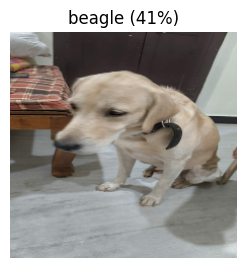

In [48]:
custom_images = [image for batch in custom_data.as_numpy_iterator() for image in batch]

plt.figure(figsize=(10, 10))
for i, image in enumerate(custom_images[:9]):
    plt.subplot(3, 3, i + 1)
    plt.imshow(image)
    plt.title(f"{custom_pred_labels[i]} ({np.max(custom_preds[i]) * 100:.0f}%)")
    plt.axis("off")
plt.show()

## 14. Summary & next steps

* Built an end-to-end image classification pipeline: raw JPEGs → `tf.data` pipeline → transfer-learning model → Kaggle submission + custom predictions.
* Frozen ResNet101V2 + a small softmax head trains quickly and generalises much better than a CNN from scratch would on 10k images.

**Ideas to improve further:**
* **Fine-tuning** — unfreeze the top blocks of ResNet with a low learning rate (e.g. `1e-5`)
* Try other backbones (EfficientNetV2, ConvNeXt) and compare
* Cache the decoded images (`.cache()`) or copy the data to the Colab VM instead of reading from Drive, to speed up training
* Deploy the Gradio demo (`app.py`) to Hugging Face Spaces